# Medical Insurance Cost Prediction
**Domain:** Healthcare Analytics  |  **Task:** Regression  |  **Target:** `charges` (medical insurance cost)

Medical insurance cost differs from person to person. In this project we build a machine learning model that predicts
an individual's insurance charges from attributes such as age, BMI, smoking habit, number of children and region.



In [3]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression,Ridge
from sklearn.ensemble import RandomForestClassifier, GradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (7, 4)
BLUE="#2a6fbb"
ORANGE="#d9822b"
SMOKER_COLORS={"no": BLUE, "yes": ORANGE}


## 1. Loading the data
We use the public **Medical Cost Personal Dataset** (1,338 records). It is the widely used `insurance.csv` file (origibally from the book *Machine Learning by Brett Lantz, also available on Kaggle.).

In [4]:
df = pd.read_csv("insurance.csv")

In [5]:
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [6]:
df.shape

(1338, 7)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB


In [9]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


## 3. Exploratory Data Analysis (EDA)

**3.1 Distribution of insurance charges**

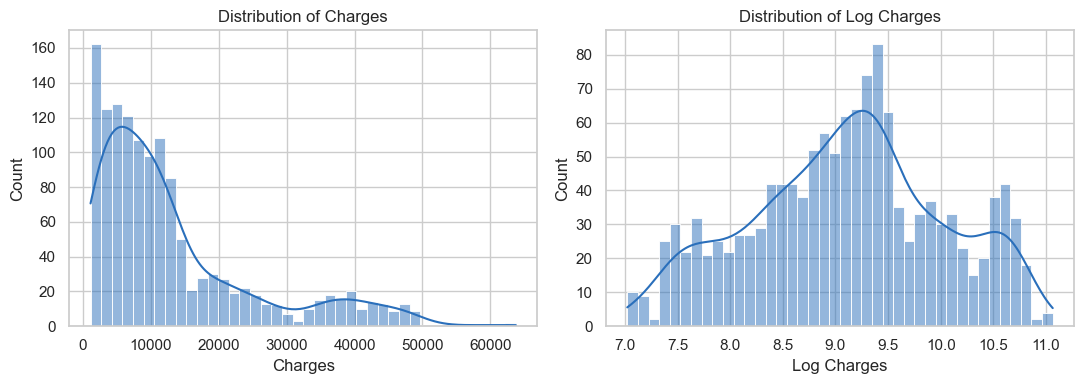

Skewness of Charges: 1.5158796580240388 2
Median charge: 9382.03 | Mean charge: 13270.42


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["charges"],bins=40,kde=True,color=BLUE,ax=ax[0])
ax[0].set_title("Distribution of Charges")
ax[0].set_xlabel("Charges")

sns.histplot(np.log(df["charges"]),bins=40,kde=True,color=BLUE,ax=ax[1])
ax[1].set_title("Distribution of Log Charges")
ax[1].set_xlabel("Log Charges")

plt.tight_layout()
plt.show()

print("Skewness of Charges:", df["charges"].skew(),2)
print("Median charge:",round(df["charges"].median(),2),"| Mean charge:",round(df["charges"].mean(),2))



***Observation:*** Charges are strongly right-skewed.Most people pay a lower amount, while asmaller group pays very high amounts. The mean is higher than the media because of this long tail 

**3.2 Age Vs Charges**

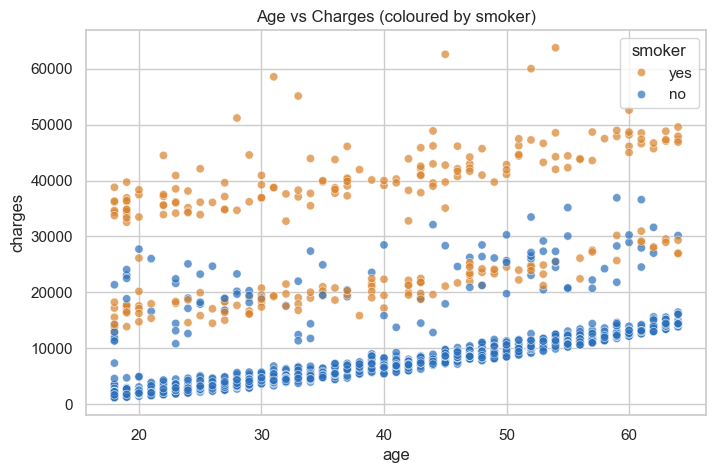

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df,x="age",y="charges",hue="smoker",palette=SMOKER_COLORS,alpha=0.7)
plt.title("Age vs Charges (coloured by smoker)")
plt.show()

**observation:** Charge increase Steadily with age. We can see three loose bands:non-smokers at the bottom,a middle band,and at the top.This shows that smoking changes the cost a lot at every age.

 **3.3 BMI and Smoking VS Charges**

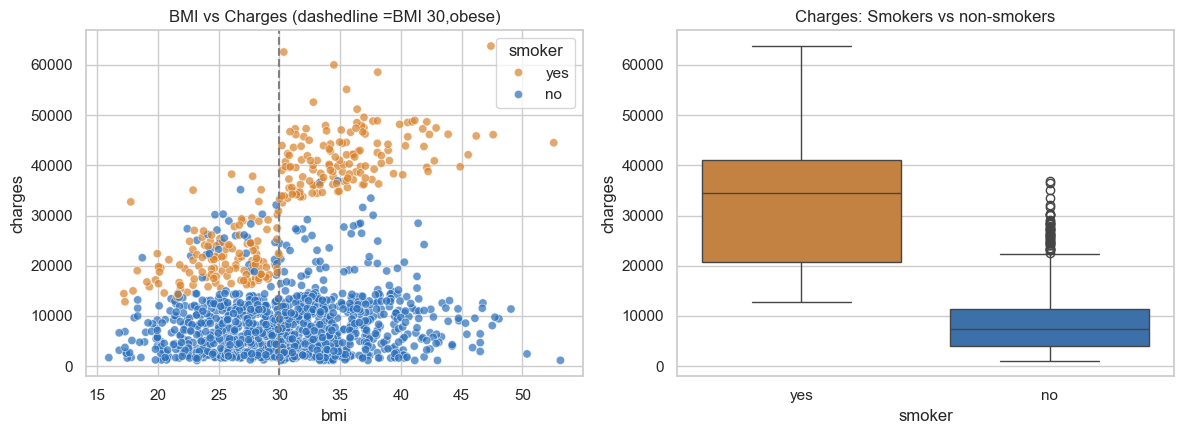

smoker
no      8434.0
yes    32050.0
Name: charges, dtype: float64


In [13]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.scatterplot(data=df,x="bmi",y="charges",hue="smoker",palette=SMOKER_COLORS,alpha=0.7,ax=ax[0])
ax[0].axvline(x=30, color="gray", linestyle="--")
ax[0].set_title("BMI vs Charges (dashedline =BMI 30,obese)")
sns.boxplot(data=df,x="smoker",y="charges",palette=SMOKER_COLORS,ax=ax[1])
ax[1].set_title("Charges: Smokers vs non-smokers")

plt.tight_layout()
plt.show()

print(df.groupby("smoker")["charges"].mean().round(0))

**observation:** Smoker pay far more than non-smokers on average. For non-smoker,BMI has little effect on charges.
for smokers, charge jump when BMI goes above 30.so **smoking + high BMI together** is the most expensive group.

**3.4 Region and demographic categories**

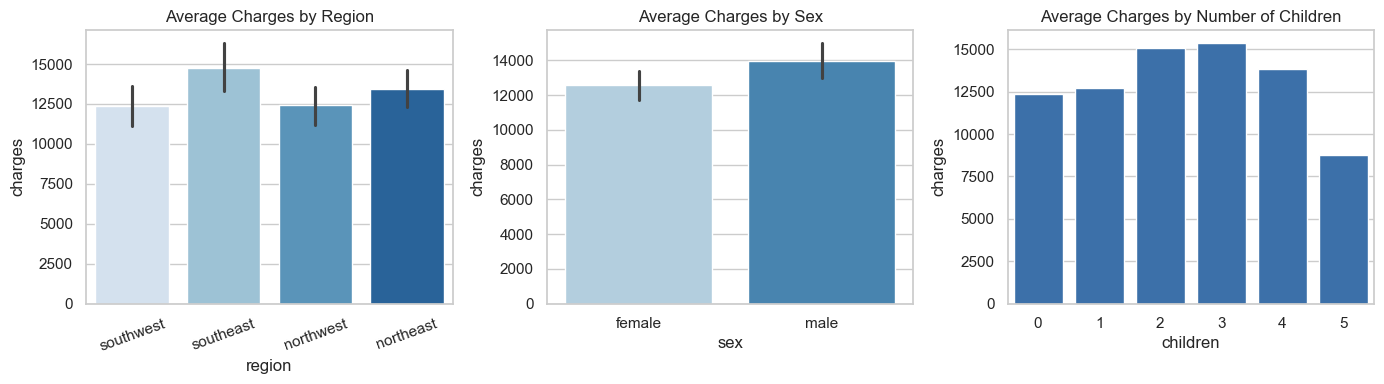

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.barplot(data=df,x="region",y="charges",palette="Blues",ax=ax[0])
ax[0].set_title("Average Charges by Region")
ax[0].tick_params(axis='x', rotation=20)
sns.barplot(data=df,x="sex",y="charges",palette="Blues",ax=ax[1])
ax[1].set_title("Average Charges by Sex")

sns.barplot(data=df,x="children",y="charges",color=BLUE,errorbar=None,ax=ax[2])
ax[2].set_title("Average Charges by Number of Children")

plt.tight_layout()
plt.show()

In [18]:
print(pd.crosstab(df["region"],df["smoker"],normalize="index").round(2))
print()
print(pd.crosstab(df["sex"],df["smoker"],normalize="index").round(2))

smoker       no   yes
region               
northeast  0.79  0.21
northwest  0.82  0.18
southeast  0.75  0.25
southwest  0.82  0.18

smoker    no   yes
sex               
female  0.83  0.17
male    0.76  0.24


**observation:** Differences across regions, sex and number of children are small compared with the effects of the smoking
Part of the sexand region difference come from the share of smokers in ecah group,not from the group itself.

**3.5 Correlation**

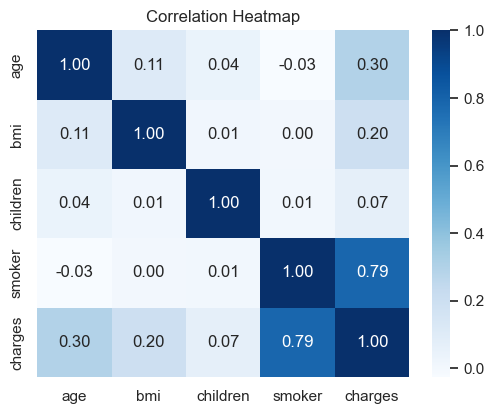

In [19]:
corr_df=df.copy()
corr_df["smoker"]=(corr_df["smoker"]=="yes").astype(int)
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_df[["age","bmi","children","smoker","charges"]].corr(),annot=True,fmt=".2f",cmap="Blues")
plt.title("Correlation Heatmap")
plt.show()

**observation:** Smoker has the strongest correlation with charges,then age, then bmi.
children has a very weak relationship. Correlation onl measures straigt-line relations,so it understates the smoker + BMI interaction we saw earlier.